# Notebook 03 — Evaluate on the held-out test set and export the final model

**Inputs:** `models/candidate_model.joblib`, `data/processed/train.csv`, `data/processed/test.csv` (from Notebook 02)

**Steps**
1. Choose an **emergency safety threshold** using cross-validation on the *training* set only.
2. Evaluate **once** on the held-out test set: classification report, **confusion matrix**, **emergency recall**.
3. **Safety analysis:** how often does the model *under-triage* (e.g. says *pharmacy* when the truth is *clinic*)?
4. Results **per language** (English vs Kiswahili).
5. **Robustness tests** on new tricky phrasings (typos, Sheng/code-mixing, negation).
6. **Confidence analysis**, which is used to decide when the backend should rely on Gemini instead.
7. Retrain on all data and **export** `models/triage_model.joblib` for the FastAPI service.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
PROCESSED_DIR = ROOT / 'data' / 'processed'
MODELS_DIR    = ROOT / 'models'
REPORTS_DIR   = ROOT / 'reports'
FIGURES_DIR   = REPORTS_DIR / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

TRIAGE_LEVELS = ['self-care', 'pharmacy', 'clinic', 'emergency']
SEVERITY = {level: i for i, level in enumerate(TRIAGE_LEVELS)}   # 0 = least urgent, 3 = most urgent
RANDOM_STATE = 42
N_JOBS = 1

bundle = joblib.load(MODELS_DIR / 'candidate_model.joblib')
model = bundle['model']
print('Model:', bundle['model_name'])
print('Best parameters:', bundle['best_params'])
print(f"CV macro-F1: {bundle['cv_f1_macro']:.3f}   CV emergency recall: {bundle['cv_emergency_recall']:.3f}")

train_df = pd.read_csv(PROCESSED_DIR / 'train.csv')
test_df  = pd.read_csv(PROCESSED_DIR / 'test.csv')
X_train, y_train = train_df['text'], train_df['triage']
X_test,  y_test  = test_df['text'],  test_df['triage']
print(f'Train: {len(train_df)}   Test (held out): {len(test_df)}')

Model: Logistic Regression
Best parameters: {'clf__C': 10, 'features__words__ngram_range': (1, 1)}
CV macro-F1: 0.854   CV emergency recall: 0.762
Train: 1166   Test (held out): 292


## 1. Emergency safety threshold
Normally a model picks the level with the highest probability. For safety we add one rule:

> **If the probability of *emergency* is at least *t*, predict emergency** even if another level scores higher.

A lower *t* catches more emergencies but raises more false alarms. *t* is chosen using **cross-validated predictions on the training set**, so the test set stays untouched.
We pick the **highest** *t* that still gives **≥ 95 % emergency recall**, which keeps false alarms as low as possible.

In [2]:
classes = list(model.classes_)
EMERG_IDX = classes.index('emergency')

def apply_rule(proba, threshold):
    # argmax prediction, overridden to 'emergency' when P(emergency) >= threshold
    pred = np.array(classes)[proba.argmax(axis=1)]
    if threshold is not None:
        pred = np.where(proba[:, EMERG_IDX] >= threshold, 'emergency', pred)
    return pred

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_proba = cross_val_predict(clone(model), X_train, y_train, cv=cv, method='predict_proba', n_jobs=N_JOBS)

rows = []
for t in [None, 0.5, 0.4, 0.35, 0.3, 0.25, 0.2, 0.15, 0.1]:
    pred = apply_rule(cv_proba, t)
    rows.append({
        'threshold': 'argmax only' if t is None else t,
        'emergency recall':    recall_score(y_train, pred, labels=['emergency'], average='macro', zero_division=0),
        'emergency precision': precision_score(y_train, pred, labels=['emergency'], average='macro', zero_division=0),
        'macro-F1':            f1_score(y_train, pred, average='macro'),
        'false alarms':        int(((pred == 'emergency') & (y_train != 'emergency')).sum()),
    })
threshold_table = pd.DataFrame(rows)
threshold_table.to_csv(REPORTS_DIR / 'emergency_threshold_cv.csv', index=False)
threshold_table.round(3)

,threshold,emergency recall,emergency precision,macro-F1,false alarms
0,argmax only,0.762,0.762,0.854,19
1,0.5,0.762,0.762,0.854,19
2,0.4,0.762,0.744,0.850,21
3,0.35,0.788,0.716,0.848,25
4,0.3,0.825,0.695,0.850,29
5,0.25,0.850,0.660,0.849,35
6,0.2,0.888,0.612,0.845,45
7,0.15,0.925,0.578,0.837,54
8,0.1,0.950,0.494,0.816,78


In [3]:
TARGET_RECALL = 0.95
numeric = threshold_table[threshold_table['threshold'] != 'argmax only']
ok = numeric[numeric['emergency recall'] >= TARGET_RECALL]

argmax_recall = threshold_table.loc[0, 'emergency recall']
if argmax_recall >= TARGET_RECALL:
    EMERGENCY_THRESHOLD = 0.5      # argmax already safe; keep a mild rule
elif not ok.empty:
    EMERGENCY_THRESHOLD = float(ok['threshold'].max())
else:                              # target not reachable: use the threshold with the best recall
    EMERGENCY_THRESHOLD = float(numeric.sort_values(['emergency recall', 'threshold'], ascending=False).iloc[0]['threshold'])

print('Chosen emergency threshold:', EMERGENCY_THRESHOLD)

Chosen emergency threshold: 0.1


## 2. One-time evaluation on the held-out test set

In [4]:
test_proba = model.predict_proba(X_test)
pred_plain = apply_rule(test_proba, None)
pred_safe  = apply_rule(test_proba, EMERGENCY_THRESHOLD)

def summary(y_true, y_pred):
    return {
        'accuracy':            accuracy_score(y_true, y_pred),
        'precision (macro)':   precision_score(y_true, y_pred, average='macro', zero_division=0),
        'recall (macro)':      recall_score(y_true, y_pred, average='macro', zero_division=0),
        'F1 (macro)':          f1_score(y_true, y_pred, average='macro'),
        'F1 (weighted)':       f1_score(y_true, y_pred, average='weighted'),
        'emergency recall':    recall_score(y_true, y_pred, labels=['emergency'], average='macro', zero_division=0),
        'emergency precision': precision_score(y_true, y_pred, labels=['emergency'], average='macro', zero_division=0),
    }

test_summary = pd.DataFrame({
    'argmax only': summary(y_test, pred_plain),
    f'with safety rule (t={EMERGENCY_THRESHOLD})': summary(y_test, pred_safe),
})
test_summary.round(3)

,argmax only,with safety rule (t=0.1)
accuracy,0.904,0.846
precision (macro),0.851,0.759
recall (macro),0.865,0.795
F1 (macro),0.855,0.742
F1 (weighted),0.904,0.857
emergency recall,0.850,0.950
emergency precision,0.773,0.396


In [5]:
# Per-class report (the final model uses the safety rule)
report = pd.DataFrame(classification_report(y_test, pred_safe, labels=TRIAGE_LEVELS,
                                            output_dict=True, zero_division=0)).T
report = report.loc[TRIAGE_LEVELS + ['macro avg', 'weighted avg']]
report['support'] = report['support'].astype(int)
report.to_csv(REPORTS_DIR / 'test_classification_report.csv')
report.round(3)

,precision,recall,f1-score,support
self-care,0.739,0.607,0.667,28
pharmacy,0.941,0.686,0.793,70
clinic,0.959,0.937,0.948,174
emergency,0.396,0.950,0.559,20
macro avg,0.759,0.795,0.742,292
weighted avg,0.895,0.846,0.857,292


## 3. Confusion matrix
Rows are the **true** level and columns the **predicted** level. The diagonal shows correct predictions.
Cells **below** the diagonal are *under-triage* (predicted less urgent than the truth), which is the dangerous direction.

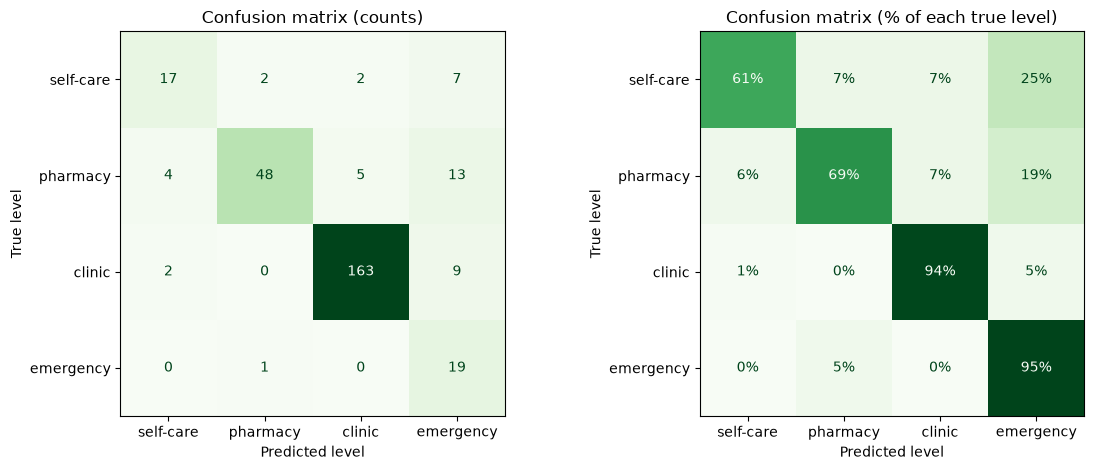

In [6]:
cm = confusion_matrix(y_test, pred_safe, labels=TRIAGE_LEVELS)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ConfusionMatrixDisplay(cm, display_labels=TRIAGE_LEVELS).plot(ax=axes[0], cmap='Greens', colorbar=False)
axes[0].set_title('Confusion matrix (counts)')

ConfusionMatrixDisplay.from_predictions(y_test, pred_safe, labels=TRIAGE_LEVELS, normalize='true',
                                        values_format='.0%', cmap='Greens', colorbar=False, ax=axes[1])
axes[1].set_title('Confusion matrix (% of each true level)')
for ax in axes:
    ax.set_xlabel('Predicted level')
    ax.set_ylabel('True level')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'confusion_matrix.png', dpi=200)
plt.show()

## 4. Safety analysis: under-triage vs over-triage
- **Under-triage:** the model says a *less* urgent level than the truth (e.g. pharmacy instead of clinic). This could delay care.
- **Over-triage:** the model says a *more* urgent level than the truth. This is safe but wastes resources.

In [7]:
true_sev = y_test.map(SEVERITY).to_numpy()
pred_sev = pd.Series(pred_safe).map(SEVERITY).to_numpy()

n = len(y_test)
safety = pd.DataFrame({
    'count': [int((pred_sev == true_sev).sum()), int((pred_sev > true_sev).sum()), int((pred_sev < true_sev).sum()),
              int(((true_sev == 3) & (pred_sev < 3)).sum())],
}, index=['correct', 'over-triage (safe side)', 'under-triage (risky side)', 'missed emergencies'])
safety['% of test set'] = (safety['count'] / n * 100).round(1)
safety

,count,% of test set
correct,247,84.6
over-triage (safe side),38,13.0
under-triage (risky side),7,2.4
missed emergencies,1,0.3


In [8]:
# Every under-triaged example, for discussion in the report
under = test_df.assign(predicted=pred_safe,
                       confidence=test_proba.max(axis=1).round(2))[pred_sev < true_sev]
pd.set_option('display.max_colwidth', 120)
under[['text', 'language', 'triage', 'predicted', 'confidence']].rename(columns={'triage': 'true'})

,text,language,true,predicted,confidence
3,My child has a mild cough and runny nose and I need a children's cough syrup.,en,pharmacy,self-care,0.98
81,I have itchy watery eyes and sneezing every time the season changes.,en,pharmacy,self-care,0.50
147,Nimepungua uzito bila sababu na sina hamu ya kula.,sw,clinic,self-care,0.64
148,"I often sneeze and have a runny nose. My eyes are scratchy and frequently runny, and I frequently cough. My head hur...",en,pharmacy,self-care,0.75
236,"I have a runny nose and I am sneezing all the time. My eyes are itchy and often watery, and I am coughing all the ti...",en,pharmacy,self-care,0.63
247,Ninakojoa kwa shida na mkojo unatoka kwa nguvu kidogo.,sw,clinic,self-care,0.71
250,Nimeungua kwa mafuta moto kifuani na mikononi na ngozi inachubuka.,sw,emergency,pharmacy,0.33


## 5. Results per language

In [9]:
lang_rows = []
for lang, part in test_df.assign(pred=pred_safe).groupby('language'):
    lang_rows.append({
        'language': {'en': 'English', 'sw': 'Kiswahili'}.get(lang, lang),
        'test examples': len(part),
        'accuracy': accuracy_score(part['triage'], part['pred']),
        'F1 (macro)': f1_score(part['triage'], part['pred'], average='macro'),
        'emergency recall': recall_score(part['triage'], part['pred'], labels=['emergency'],
                                         average='macro', zero_division=0),
    })
per_language = pd.DataFrame(lang_rows)
per_language.to_csv(REPORTS_DIR / 'test_per_language.csv', index=False)
per_language.round(3)

,language,test examples,accuracy,F1 (macro),emergency recall
0,English,269,0.888,0.779,1.0
1,Kiswahili,23,0.348,0.303,0.8


## 6. Robustness tests (new, tricky phrasings)
These sentences are **not** in the dataset. They test typos, Sheng and code-mixing, negation and vague wording, all common in real chats.
The expected levels are the developer's judgement.

In [10]:
robustness = pd.DataFrame([
    ('i hav chest pein and i cant breath well',                         'emergency', 'typos'),
    ('my child is convulsing and wont wake up',                         'emergency', 'paraphrase'),
    ('Nimeumwa na nyoka na mguu umevimba sana',                         'emergency', 'kiswahili'),
    ('Niko na homa na kichwa inauma tangu jana',                        'clinic',    'sheng / informal'),
    ('nimekuwa na fever na chills for 3 days',                          'clinic',    'code-mixed'),
    ('mtoto ana diarrhoea lakini anakunywa maji vizuri',                'pharmacy',  'code-mixed'),
    ('I have a burning pain when I pee',                                'clinic',    'informal'),
    ('heartburn after eating chapati and beans',                        'pharmacy',  'local food'),
    ('I just have a small cold, nothing serious',                       'self-care', 'paraphrase'),
    ('no chest pain, just a mild headache from stress',                 'self-care', 'negation'),
    ('I feel unwell',                                                   'clinic',    'vague'),
    ('My leg is broken, the bone is out',                               'emergency', 'paraphrase'),
], columns=['text', 'expected', 'type'])

r_proba = model.predict_proba(robustness['text'])
robustness['predicted'] = apply_rule(r_proba, EMERGENCY_THRESHOLD)
robustness['confidence'] = r_proba.max(axis=1).round(2)
robustness['correct'] = np.where(robustness['predicted'] == robustness['expected'], '✅', '❌')
robustness.to_csv(REPORTS_DIR / 'robustness_tests.csv', index=False)

print(f"Robustness: {(robustness['correct'] == '✅').sum()} / {len(robustness)} correct")
robustness

Robustness: 8 / 12 correct


,text,expected,type,predicted,confidence,correct
0,i hav chest pein and i cant breath well,emergency,typos,emergency,0.55,✅
1,my child is convulsing and wont wake up,emergency,paraphrase,emergency,0.74,✅
2,Nimeumwa na nyoka na mguu umevimba sana,emergency,kiswahili,emergency,0.88,✅
3,Niko na homa na kichwa inauma tangu jana,clinic,sheng / informal,emergency,0.41,❌
4,nimekuwa na fever na chills for 3 days,clinic,code-mixed,emergency,0.81,❌
5,mtoto ana diarrhoea lakini anakunywa maji vizuri,pharmacy,code-mixed,emergency,0.51,❌
6,I have a burning pain when I pee,clinic,informal,clinic,0.62,✅
7,heartburn after eating chapati and beans,pharmacy,local food,pharmacy,0.67,✅
8,"I just have a small cold, nothing serious",self-care,paraphrase,self-care,0.86,✅
9,"no chest pain, just a mild headache from stress",self-care,negation,self-care,0.80,✅


## 7. Confidence analysis
Is the model more accurate when it is more confident? If so, the backend can **trust confident predictions** and **rely more on Gemini when the model is unsure**.

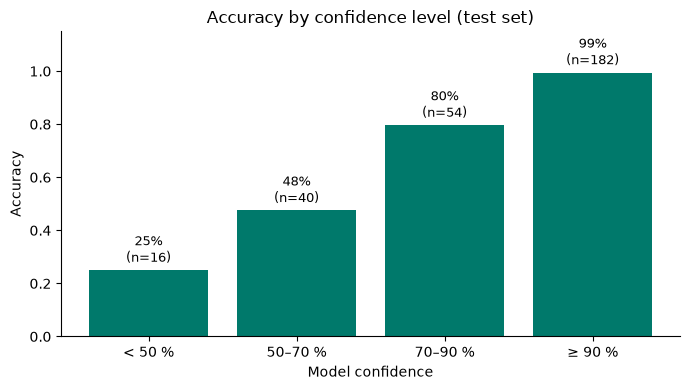

,examples,accuracy,% of test set
bucket,,,
< 50 %,16,0.250,5.5
50–70 %,40,0.475,13.7
70–90 %,54,0.796,18.5
≥ 90 %,182,0.995,62.3


In [11]:
conf = test_proba.max(axis=1)
bins = [0, 0.5, 0.7, 0.9, 1.0]
labels = ['< 50 %', '50–70 %', '70–90 %', '≥ 90 %']
conf_df = pd.DataFrame({'confidence': conf, 'correct': pred_safe == y_test.to_numpy()})
conf_df['bucket'] = pd.cut(conf_df['confidence'], bins=bins, labels=labels, include_lowest=True)

conf_table = conf_df.groupby('bucket', observed=False).agg(examples=('correct', 'size'), accuracy=('correct', 'mean'))
conf_table['% of test set'] = (conf_table['examples'] / len(conf_df) * 100).round(1)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(conf_table.index.astype(str), conf_table['accuracy'].fillna(0), color='#00796b')
ax.bar_label(bars, labels=[f'{a:.0%}\n(n={n})' if n else 'n=0' for a, n in zip(conf_table['accuracy'].fillna(0), conf_table['examples'])], padding=3, fontsize=9)
ax.set_ylim(0, 1.15)
ax.set_xlabel('Model confidence')
ax.set_ylabel('Accuracy')
ax.set_title('Accuracy by confidence level (test set)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'confidence_vs_accuracy.png', dpi=200)
plt.show()
conf_table.round(3)

## 8. Export the final model
The test results above come from the model trained on the **training set only**. For deployment, the same settings are **re-trained on all the data** (train + test), which is standard practice once evaluation is finished.
The reported metrics remain the held-out test results.

In [12]:
all_df = pd.concat([train_df, test_df], ignore_index=True)
final_model = clone(model).fit(all_df['text'], all_df['triage'])

final_metrics = summary(y_test, pred_safe)
export = {
    'model': final_model,
    'model_name': bundle['model_name'],
    'version': datetime.now(timezone.utc).strftime('%Y%m%d-%H%M'),
    'labels': TRIAGE_LEVELS,
    'emergency_threshold': EMERGENCY_THRESHOLD,
    'trained_on': len(all_df),
    'sklearn_version': sklearn.__version__,
    'test_metrics': {k: round(float(v), 4) for k, v in final_metrics.items()},
}
joblib.dump(export, MODELS_DIR / 'triage_model.joblib')

with open(REPORTS_DIR / 'final_model_card.json', 'w', encoding='utf-8') as f:
    json.dump({k: v for k, v in export.items() if k != 'model'}
              | {'best_params': {k: str(v) for k, v in bundle['best_params'].items()},
                 'test_examples': len(test_df)}, f, indent=2)

print('Saved models/triage_model.joblib')
print(json.dumps(export['test_metrics'], indent=2))

Saved models/triage_model.joblib
{
  "accuracy": 0.8459,
  "precision (macro)": 0.7587,
  "recall (macro)": 0.7949,
  "F1 (macro)": 0.7416,
  "F1 (weighted)": 0.8571,
  "emergency recall": 0.95,
  "emergency precision": 0.3958
}


In [13]:
# Final check: load the exported file exactly as the API will, and predict
loaded = joblib.load(MODELS_DIR / 'triage_model.joblib')
m, t = loaded['model'], loaded['emergency_threshold']

def triage(text):
    p = m.predict_proba([text])[0]
    cls = list(m.classes_)
    level = 'emergency' if p[cls.index('emergency')] >= t else cls[int(p.argmax())]
    return {'triage': level, 'confidence': round(float(p.max()), 3),
            'probabilities': {c: round(float(x), 3) for c, x in zip(cls, p)}}

for s in ['I have a mild cold and a runny nose',
          'Nina maumivu makali ya kifua na siwezi kupumua']:
    print(s, '->', triage(s))

I have a mild cold and a runny nose -> {'triage': 'self-care', 'confidence': 0.994, 'probabilities': {'clinic': 0.0, 'emergency': 0.0, 'pharmacy': 0.005, 'self-care': 0.994}}
Nina maumivu makali ya kifua na siwezi kupumua -> {'triage': 'emergency', 'confidence': 0.988, 'probabilities': {'clinic': 0.006, 'emergency': 0.988, 'pharmacy': 0.005, 'self-care': 0.001}}


## Observations (fill in for the report)
- **Test macro-F1 and emergency recall:** how close are they to the cross-validation scores from Notebook 02? (Close means the model is not over-fitted.)
- **Confusion matrix:** which levels are confused most often? Usually it is the neighbours, *pharmacy ↔ clinic* or *self-care ↔ pharmacy*.
- **Safety:** how many emergencies were missed, and what did they look like?
- **Kiswahili vs English:** is performance lower for Kiswahili, and why (fewer training examples)?
- **Robustness:** which tricky phrasings failed (negation and code-mixing are typical weaknesses of TF-IDF models)? This motivates the **hybrid design**, where Gemini handles context and the ML model provides an independent safety check.
- **Limitations:** labels derived from conditions, curated examples written by one author, small Kiswahili sample, and no real-world clinical validation.